# Evaluating an interpolator

Every map invites the question of how good it is. With a truth at hand, as in a simulation, the answer is
a measure of error over the map. Without one, as in practice, it is a measure of error over held-out
data. The module `spatialize.evaluation` provides both, for Spatialize and for any other interpolator, with
scenarios with a known truth, metrics for amounts and for categories, cross-validation of any
prediction function, and classical baselines to set beside the ensemble.

## Learning goals

- How to build a scenario with a known truth, in two or three dimensions, for amounts or categories.
- Which metrics the module gives, and how its normalised metrics read.
- How to cross-validate any interpolator, Spatialize or another, with one call.
- How to evaluate a categorical estimate, and what the averaging of its metrics means.
- Which baselines the module offers, and what they cost.

*How good is a map, with a truth and without one?*

## The idea

An interpolator is a function from data to predictions, `f(points, values, xi)`. Everything here is
built on that signature, so Spatialize, SciPy, kriging or a function of your own are evaluated alike.
With a truth, the metrics compare the map with it location by location. Without one, cross-validation
holds each datum out, or each fold of data, predicts it from the rest, and compares, which measures the
error where the data are rather than over the whole map.

## Step by step

### A scenario with a truth

`SyntheticScenario` draws data from a known function and gives its values on a grid, in two or three
dimensions, for amounts (`kind="cubic"`) or for categories (`categorical=True`).

200 data, 3600 grid nodes, truth from -0.191 to 0.248


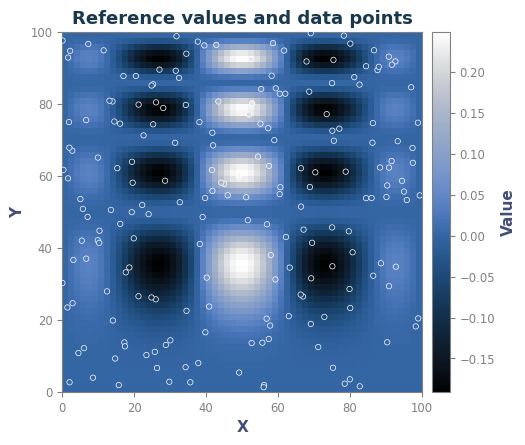

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.evaluation import (SyntheticScenario, MAE, RMSE, bias, R2, op_mae, op_rmse,
                                   accuracy, precision, recall, f1_score,
                                   loo_validation, kfold_validation, scipy_prediction, auto_scipy_prediction)
from spatialize.gs.esi import esi_nongriddata
from spatialize.gs.cat_esi import cat_esi_nongriddata
from spatialize.viz import plot_categorical_colormap

spatialize.session.set(empty_cells="coarsen", progress=False)

scenario = SyntheticScenario(n_dims=2, extent=[0, 100, 0, 100], griddata=False, n_grid_points=60)
points, values, xi, truth = scenario.simulate_scenario(n_samples=200, seed=1)
print(f"{len(values)} data, {len(xi)} grid nodes, truth from {truth.min():.3f} to {truth.max():.3f}")
scenario.plot_2d_scenario(points, values, xi, truth)
plt.show()

### Metrics for amounts

Every metric takes the truth and the prediction, `metric(true, pred)`, and leaves out the locations where
either is missing. `MAE`, `RMSE` and `bias` are in the units of the variable. `R2` compares the error with
the spread of the truth, one for a perfect map and below zero for a map worse than the mean. The
operational metrics, `op_mae` and `op_rmse`, divide the error by the range of the truth, a share that
compares maps of one field across methods.

In [2]:
predictors = {
    "Spatialize, mondrian, idw": lambda p, v, x: esi_nongriddata(p, v, x, local_interpolator="idw", exponent=2.0,
                                                                alpha=0.9, n_partitions=100, seed=0).estimation(),
    "SciPy, linear": lambda p, v, x: scipy_prediction(p, v, x, method="linear"),
    "SciPy, nearest": lambda p, v, x: scipy_prediction(p, v, x, method="nearest"),
}
maps = {name: predict(points, values, xi) for name, predict in predictors.items()}
metrics = {"MAE": MAE, "RMSE": RMSE, "bias": bias, "R2": R2, "op_mae": op_mae, "op_rmse": op_rmse}
table = pd.DataFrame({name: {m: f(truth, z) for m, f in metrics.items()} for name, z in maps.items()}).T
table["share of the map without a value"] = [np.mean(np.isnan(z)) for z in maps.values()]
everywhere = np.all([~np.isnan(z) for z in maps.values()], axis=0)          # the nodes every method predicts
table["MAE on the nodes all predict"] = [MAE(truth[everywhere], z[everywhere]) for z in maps.values()]
table.round(4)

,MAE,RMSE,bias,R2,op_mae,op_rmse,share of the map without a value,MAE on the nodes all predict
"Spatialize, mondrian, idw",0.0241,0.0406,0.0011,0.6812,0.0548,0.0926,0.0000,0.0260
"SciPy, linear",0.0213,0.0360,0.0012,0.7745,0.0485,0.0821,0.1017,0.0213
"SciPy, nearest",0.0258,0.0422,0.0020,0.6556,0.0588,0.0962,0.0000,0.0276


On this smooth field SciPy's linear interpolation gives the smallest errors, 0.021 against 0.024 for the
ensemble, the triangulation suiting a surface with no edges. Its share of the map without a value, 10 %,
matters. Over the nodes all three predict the ensemble's error rises to 0.026, the edges counting, while
SciPy's linear interpolation stays at 0.021. `R2` reads 0.68 to 0.77, and the operational metrics put
the errors at 5 % to 6 % of the range of the field.

### Cross-validation of any interpolator

`loo_validation` holds out each datum in turn, `kfold_validation` each of `k` folds, and both call the
prediction function on the rest. They return a dictionary of metrics, and the held-out predictions when
`return_predictions=True`.

In [3]:
rows, held_out = {}, {}
for name, predict in predictors.items():
    loo = loo_validation(points, values, predict)
    folds, held_out[name] = kfold_validation(points, values, predict, k=5, seed=0, return_predictions=True)
    rows[name] = {"leave-one-out MAE": loo["MAE"], "five-fold MAE": folds["MAE"], "MAE against the truth": table.loc[name, "MAE"]}
pd.DataFrame(rows).T.round(4)

,leave-one-out MAE,five-fold MAE,MAE against the truth
"Spatialize, mondrian, idw",0.0242,0.0262,0.0241
"SciPy, linear",0.0215,0.0246,0.0213
"SciPy, nearest",0.0272,0.0324,0.0258


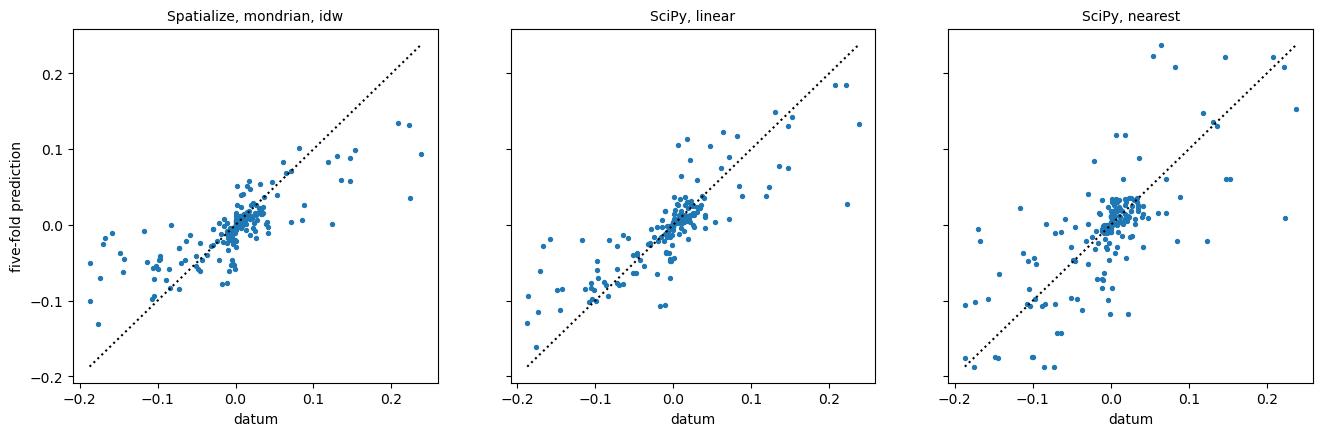

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes, held_out.items()):
    ax.scatter(values, pred, s=8)
    ax.plot([values.min(), values.max()], [values.min(), values.max()], "k:")
    ax.set_title(name, fontsize=10); ax.set_xlabel("datum")
axes[0].set_ylabel("five-fold prediction")
plt.show()

Cross-validation ranks the three methods as the truth does, the linear interpolation first and the
nearest datum last. Leave-one-out comes within a ten-thousandth of the error against the truth, while
five folds, each leaving out a fifth of the data, run a little higher. The held-out predictions follow
the diagonal, those of the nearest datum spreading most.

### Categories

A categorical scenario holds four classes in a spiral. The metrics for categories, `accuracy`,
`precision`, `recall` and `f1_score`, take an `average`. The weighted average counts each class by its
size, so a large class dominates, while the macro average counts every class alike, so a small class
that the map misses weighs as much as a large one. Cross-validation detects categorical values and
reports their metrics.

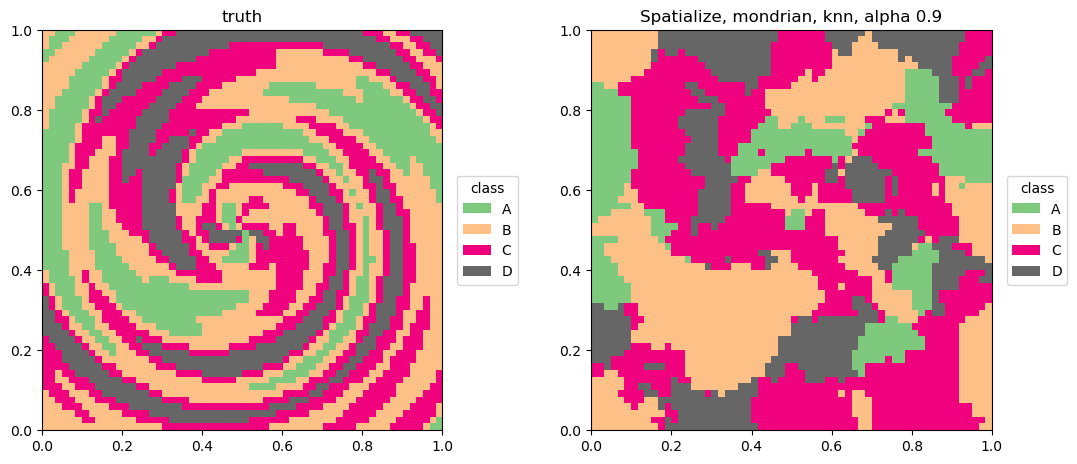

,accuracy,precision,recall,f1
weighted,0.505,0.515,0.505,0.505
macro,0.505,0.519,0.501,0.505


In [5]:
categorical = SyntheticScenario(categorical=True, n_grid_points=60)
cat_points, cat_values, cat_xi, cat_truth = categorical.simulate_scenario(n_samples=300, seed=1)
classify = lambda p, v, x: cat_esi_nongriddata(p, v, x, classifier="knn", n_partitions=100, alpha=0.9, seed=0).estimation()
cat_map = classify(cat_points, cat_values, cat_xi)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (title, z) in zip(axes, (("truth", cat_truth), ("Spatialize, mondrian, knn, alpha 0.9", cat_map))):
    plot_categorical_colormap(z, xi_locations=cat_xi, ax=ax, title=title, legend_title="class", extent=(0, 1, 0, 1))
plt.show()
pd.DataFrame({average: {"accuracy": accuracy(cat_truth, cat_map), "precision": precision(cat_truth, cat_map, average=average),
                        "recall": recall(cat_truth, cat_map, average=average), "f1": f1_score(cat_truth, cat_map, average=average)}
              for average in ("weighted", "macro")}).T.round(3)

In [6]:
pd.Series(kfold_validation(cat_points, cat_values, classify, k=5, seed=0)).round(3).to_frame("five-fold")

,five-fold
accuracy,0.433


The four classes wind in a spiral whose bands are about as narrow as the spacing between the 300 data,
so the map gets about half of the grid right, 0.505, and five-fold cross-validation, with a fifth fewer
data, 0.433. The weighted and macro averages agree here, since the four classes are about equally
frequent. The spiral is a hard test by design. A map of broad units, as in *Estimating categories*,
gets far more right.

### Baselines

The module offers classical interpolators with the same signature. `scipy_prediction` runs SciPy's
`griddata` with a given method, and `auto_scipy_prediction` chooses the method by leave-one-out.
`kriging_prediction` runs PyKrige with given settings, and `auto_krige` searches its settings by
five-fold cross-validation over a grid of 96 combinations, which takes minutes on a few hundred data. A
smaller grid of your own, as in the tutorial *Beyond the classical interpolators*, takes seconds.

In [7]:
auto = auto_scipy_prediction(points, values, xi)
covered = ~np.isnan(auto)
pd.Series({"MAE of auto_scipy_prediction on the nodes it predicts": MAE(truth, auto),
           "share of the map without a value": np.mean(~covered),
           "MAE of the ensemble on the same nodes": MAE(truth[covered], maps["Spatialize, mondrian, idw"][covered])}).round(4).to_frame()

,0
MAE of auto_scipy_prediction on the nodes it predicts,0.0144
share of the map without a value,0.1017
MAE of the ensemble on the same nodes,0.0260


`auto_scipy_prediction` chose by leave-one-out the cubic interpolation, whose error, 0.014, is the
smallest here, on the 90 % of the map it predicts. On those same nodes the ensemble's error is 0.026. On a
smooth surface away from its edges the cubic interpolation is hard to beat, while its share of the map
left empty grows with the gaps between the data.

## Pitfalls

- **Missing values left out of a metric.** A method that leaves part of the map without a value, as
  SciPy does outside the triangulation of the data, is scored on the rest only, often the easier part.
  Compare methods on the locations every one of them predicts.
- **A cross-validation error read as the map's error.** Held-out data lie where data are, closer to their
  neighbours than most of the map. Use cross-validation to choose and to rank, not to promise an error.
- **Operational metrics across fields.** They divide by the range of the truth, which differs from one
  field to another. Compare them within one field.
- **The weighted average on unbalanced categories.** A large class can hide a small one the map misses.
  Read the macro average beside it.
- **A slow baseline.** `auto_krige` searches 96 settings. Pass a smaller grid of your own when time
  matters.

## Try it yourself

1. Run the scenario in three dimensions (`SyntheticScenario(n_dims=3, extent=[0, 10, 0, 10, 0, 5])`)
   and cross-validate the ensemble.
2. Pass your own function to `simulate_scenario(custom_func=...)` and evaluate the maps again.
3. Add a decoder of your own to `predictors` and compare.

## Next

- *Beyond the classical interpolators*, for a comparison on fields of two kinds.
- *Choosing an ensemble with the Pareto search*, for cross-validation inside the search.
- *Plotting, saving, loading*, for the figures and the results on disk.
- The documentation's [Evaluation](https://spatialize.readthedocs.io/en/latest/reference/evaluation.html)
  (reference).